# Synthetic validation of the Hodge decomposition

**Project:** Hodge-Aware Topological Deep Learning for Cell-Cell Communication (PW_27_CN_08)
**Author:** Dhriti (P3, Hodge core)

**The idea in one paragraph.** Our decomposition is a measuring instrument: it takes signalling traffic on the links between cells and splits it into three kinds, *gradient* (source to sink), *curl* (small loops) and *harmonic* (loops around holes). Before anyone trusts it on real tissue, we test it on a **toy tissue where we planted the traffic ourselves**, so we know the right answer and can measure the error. Nothing here needs real data or a GPU.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hodgecc.synth import grid_complex, planted_flows
from hodgecc.hodge import decompose, nullity_L1_dense, harmonic_residual

NAMES = ["gradient", "curl", "harmonic"]
COLORS = ["tab:blue", "tab:orange", "tab:green"]
HOLES2 = [(5.5, 5.5, 2.0), (14.5, 14.5, 2.0)]


def rel(a, b):
    return np.linalg.norm(a - b) / np.linalg.norm(b)


def errors(B1, B2, f, parts):
    g, c, h = parts
    gg, cc, hh = decompose(B1, B2, f)
    return [rel(gg, g), rel(cc, c), rel(hh, h)]


def balanced(B1, B2, seed, ratio=(1.0, 1.0, 1.0)):
    # planted flow whose three parts have the energy ratio we choose
    _, g, c, h = planted_flows(B1, B2, seed=seed)
    g = g / np.linalg.norm(g) * ratio[0]
    c = c / np.linalg.norm(c) * ratio[1]
    h = h / np.linalg.norm(h) * ratio[2]
    return g + c + h, (g, c, h)


def draw(ax, coords, edges, flow, title):
    p, q = coords[edges[:, 0]], coords[edges[:, 1]]
    mid = (p + q) / 2
    d = (q - p) * np.sign(flow)[:, None]
    s = np.abs(flow) / (np.abs(flow).max() + 1e-12)
    ax.quiver(mid[:, 0], mid[:, 1], d[:, 0], d[:, 1], s, cmap="viridis",
              angles="xy", scale_units="xy", scale=1.4, width=0.003,
              headwidth=3.5, headlength=4)
    ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")

## 0. The toy tissue

A 20 x 20 grid of "cells" joined into a triangle mesh, with **two holes** cut out (think of two glands). Each arrow is a link between two cells; its direction is the direction of signal flow and its colour is the strength. We plant a gradient, a curl and a harmonic flow, add them up, and ask the decomposition to separate them again.

cells: 400  links: 1071  triangles: 678


holes found (beta1): 2 (true: 2)


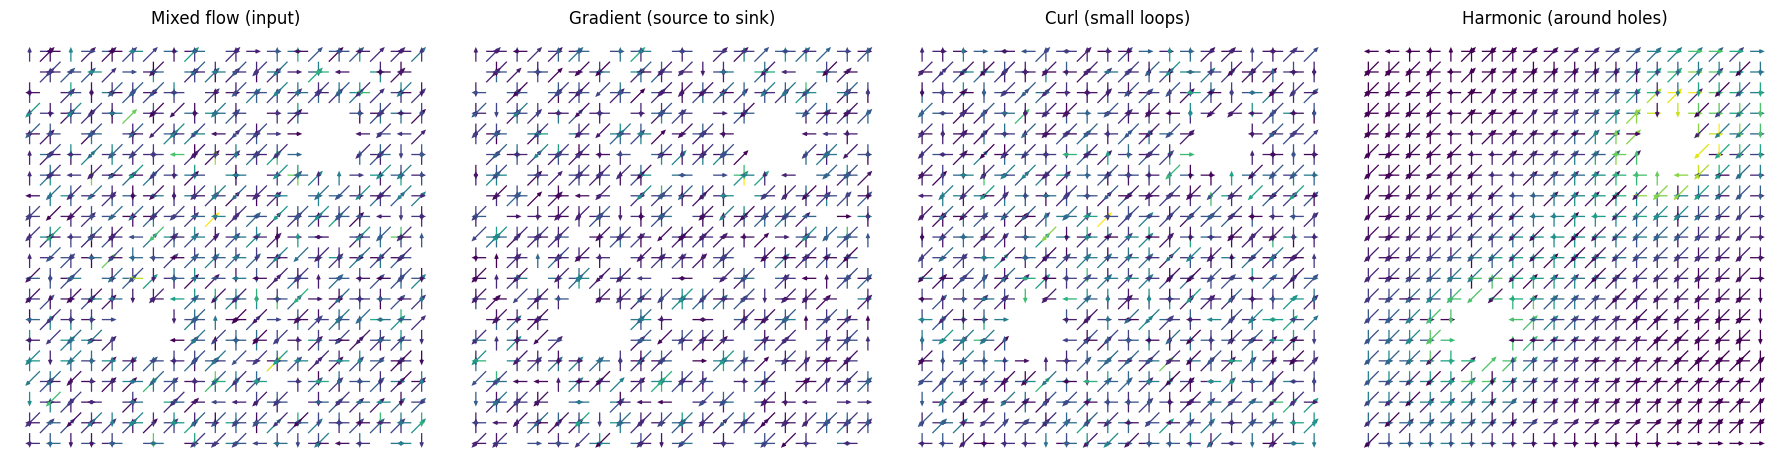

In [2]:
coords, edges, tris, B1, B2 = grid_complex(20, 20, HOLES2)
print("cells:", len(coords), " links:", len(edges), " triangles:", len(tris))
print("holes found (beta1):", nullity_L1_dense(B1, B2), "(true: 2)")

f, g, c, h = planted_flows(B1, B2, seed=1)
gg, cc, hh = decompose(B1, B2, f)

fig, axs = plt.subplots(1, 4, figsize=(18, 5))
draw(axs[0], coords, edges, f, "Mixed flow (input)")
draw(axs[1], coords, edges, gg, "Gradient (source to sink)")
draw(axs[2], coords, edges, cc, "Curl (small loops)")
draw(axs[3], coords, edges, hh, "Harmonic (around holes)")
plt.tight_layout(); plt.show()

**What to look for.** The harmonic panel is strongest around the two holes, which is where big loops live. The gradient and curl panels are spread over the whole mesh.

## 1. Known proportions, no noise

*Question:* if we mix 60% gradient, 30% curl and 10% harmonic, do we get the right parts back?

In [3]:
rows = []
for ratio in [(0.6, 0.3, 0.1), (0.2, 0.2, 0.6), (0.1, 0.1, 0.8)]:
    f, parts = balanced(B1, B2, 1, ratio)
    e = errors(B1, B2, f, parts)
    rows.append({"gradient:curl:harmonic": ratio, "err gradient": e[0],
                 "err curl": e[1], "err harmonic": e[2]})
pd.DataFrame(rows).style.format({"err gradient": "{:.1e}", "err curl": "{:.1e}",
                                 "err harmonic": "{:.1e}"})

,gradient:curl:harmonic,err gradient,err curl,err harmonic
0,"(0.6, 0.3, 0.1)",6.8e-12,3.6e-11,1.2e-10
1,"(0.2, 0.2, 0.6)",3.5e-11,7.1e-11,2.6e-11
2,"(0.1, 0.1, 0.8)",1.0e-10,1.6e-10,2.4e-11


**Reading it.** Errors of about 1e-10 mean the three parts come back essentially exactly. Without noise, the decomposition is exact.

## 2. Error vs noise

*Question:* real data is noisy. How fast does recovery degrade? SNR is signal strength divided by noise strength (high = clean). Each point is the average of 8 random trials.

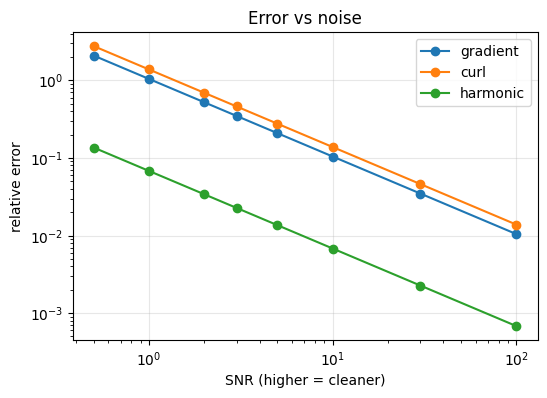

,gradient,curl,harmonic
SNR,,,
100.0,0.010,0.014,0.001
30.0,0.035,0.046,0.002
10.0,0.104,0.138,0.007
5.0,0.208,0.276,0.014
3.0,0.347,0.460,0.023
2.0,0.521,0.690,0.034
1.0,1.042,1.381,0.068
0.5,2.085,2.762,0.136


In [4]:
snrs = [100, 30, 10, 5, 3, 2, 1, 0.5]
res = np.zeros((len(snrs), 3))
for i, snr in enumerate(snrs):
    acc = []
    for seed in range(8):
        f, parts = balanced(B1, B2, seed)
        rng = np.random.default_rng(100 + seed)
        n = rng.normal(size=f.shape)
        n *= np.linalg.norm(f) / snr / np.linalg.norm(n)
        acc.append(errors(B1, B2, f + n, parts))
    res[i] = np.mean(acc, axis=0)

fig, ax = plt.subplots(figsize=(6, 4))
for y, n_, col in zip(res.T, NAMES, COLORS):
    ax.plot(snrs, y, "o-", label=n_, color=col)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("SNR (higher = cleaner)"); ax.set_ylabel("relative error")
ax.set_title("Error vs noise"); ax.legend(); ax.grid(alpha=0.3)
plt.show()
pd.DataFrame(res, index=pd.Index(snrs, name="SNR"), columns=NAMES).round(3)

**Reading it.** Gradient and curl errors grow in proportion to the noise (about 10% error at SNR 10). The harmonic part is about **15 times more robust** (under 1% at SNR 10). Reason: noise spreads over all three kinds of flow in proportion to how many directions each has. Harmonic flow has only one direction per hole, so it catches very little noise. Big-loop signal is the most noise-robust of the three.

## 3. Error and speed vs mesh size

*Question:* does it still work, and stay fast, on bigger tissue?

In [5]:
rows = []
for s in [10, 15, 20, 25, 30]:
    holes = [(s / 2 - 0.5, s / 2 - 0.5, max(1.5, s / 10))]
    _, E_, _, B1s, B2s = grid_complex(s, s, holes)
    f, parts = balanced(B1s, B2s, 1)
    t0 = time.time()
    e = errors(B1s, B2s, f, parts)
    rows.append({"grid": f"{s}x{s}", "links": len(E_), "seconds": time.time() - t0,
                 "err gradient": e[0], "err curl": e[1], "err harmonic": e[2]})
pd.DataFrame(rows).style.format({"seconds": "{:.3f}", "err gradient": "{:.1e}",
                                 "err curl": "{:.1e}", "err harmonic": "{:.1e}"})

,grid,links,seconds,err gradient,err curl,err harmonic
0,10x10,242,0.006,1.3e-11,9.7e-12,1.7e-11
1,15x15,600,0.008,1.1e-11,1.4e-11,1.7e-11
2,20x20,1096,0.017,1.4e-11,2.9e-11,3.2e-11
3,25x25,1728,0.014,2.7e-11,2.5e-11,3.7e-11
4,30x30,2510,0.028,2.9e-11,3.6e-11,4.6e-11


**Reading it.** Errors stay near 1e-11 and a solve takes a fraction of a second at 2,500 links, so cost will not be a problem at the sizes we use.

## 4. Hidden links (the baseline a learned model must beat)

*Question:* real data has missing values, and our later model will be trained to fill them in (masked flow reconstruction). If we simply treat hidden links as zero and decompose, how bad is it? This is the **do-nothing baseline** the neural network has to beat.

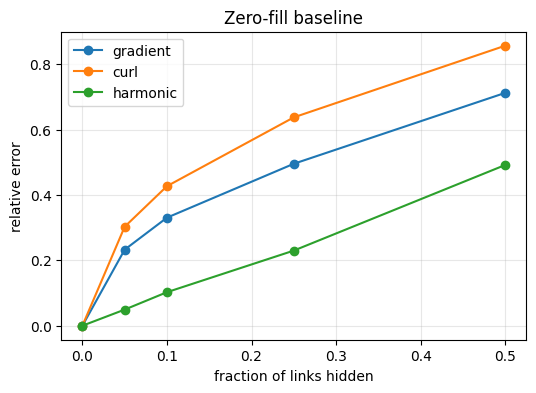

,gradient,curl,harmonic
hidden,,,
0.00,0.000,0.000,0.000
0.05,0.233,0.303,0.049
0.10,0.330,0.427,0.103
0.25,0.495,0.637,0.230
0.50,0.712,0.856,0.491


In [6]:
fracs = [0.0, 0.05, 0.1, 0.25, 0.5]
res = np.zeros((len(fracs), 3))
for i, p in enumerate(fracs):
    acc = []
    for seed in range(8):
        f, parts = balanced(B1, B2, seed)
        rng = np.random.default_rng(200 + seed)
        f_obs = f * (rng.random(f.shape) > p)
        acc.append(errors(B1, B2, f_obs, parts))
    res[i] = np.mean(acc, axis=0)

fig, ax = plt.subplots(figsize=(6, 4))
for y, n_, col in zip(res.T, NAMES, COLORS):
    ax.plot(fracs, y, "o-", label=n_, color=col)
ax.set_xlabel("fraction of links hidden"); ax.set_ylabel("relative error")
ax.set_title("Zero-fill baseline"); ax.legend(); ax.grid(alpha=0.3)
plt.show()
pd.DataFrame(res, index=pd.Index(fracs, name="hidden"), columns=NAMES).round(3)

**Reading it.** Hiding 25% of links gives about 50% error for gradient and 64% for curl, but only 23% for harmonic. These are the numbers for the learned model to improve on.

## 5. Counting holes

*Question:* does the number of holes the maths detects (beta1) match the number we cut out?

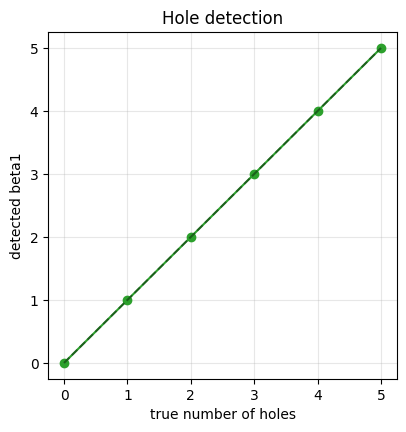

[(0, np.int64(0)), (1, np.int64(1)), (2, np.int64(2)), (3, np.int64(3)), (4, np.int64(4)), (5, np.int64(5))]


In [7]:
centres = [(7.5, 7.5), (7.5, 22.5), (22.5, 7.5), (22.5, 22.5), (15, 15)]
true_n, found = [], []
for k in range(len(centres) + 1):
    holes = [(x, y, 2.0) for x, y in centres[:k]]
    _, _, _, B1h, B2h = grid_complex(30, 30, holes)
    true_n.append(k); found.append(nullity_L1_dense(B1h, B2h))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(true_n, found, "o-", color="tab:green")
ax.plot([0, max(true_n)], [0, max(true_n)], "k--", alpha=0.4)
ax.set_xlabel("true number of holes"); ax.set_ylabel("detected beta1")
ax.set_title("Hole detection"); ax.grid(alpha=0.3)
plt.show()
print(list(zip(true_n, found)))

**Reading it.** Detected beta1 equals the true count from 0 to 5 holes.

## Summary

| Test | Result |
|---|---|
| Noise-free recovery | Exact (error about 1e-10) for gradient, curl and harmonic |
| Noise | Gradient and curl error scales with noise; harmonic is about 15 times more robust |
| Mesh size | Stays exact and fast up to thousands of links |
| Hidden links | Zero-fill baseline error is large (50-64% at 25% hidden); sets the bar for the learned model |
| Hole counting | beta1 equals the true hole count (0 to 5) |

**Limits.** These are idealised meshes with planted flows. They show the maths is implemented correctly; they do not show that real signalling has a meaningful curl or harmonic part. That is what the real-data experiments and the shuffled-flow control are for.

## 6. Real data (fill in when the DLPFC slice arrives)

Set `PATH` to the `.h5ad` file Mayur shares. The file needs `adata.obsm["spatial"]`.

In [8]:
import os
PATH = None   # e.g. r"C:\path\to\dlpfc_151673.h5ad"

if PATH and os.path.exists(PATH):
    import scanpy as sc, gudhi
    from hodgecc.complex import build_complex
    adata = sc.read_h5ad(PATH)
    edges_r, tris_r, B1r, B2r = build_complex(adata.obsm["spatial"],
                                              method="grid", adata=adata)
    n = adata.n_obs
    st = gudhi.SimplexTree()
    for i in range(n): st.insert([i])
    for a in edges_r: st.insert([int(a[0]), int(a[1])])
    for t in tris_r: st.insert([int(x) for x in t])
    st.compute_persistence()
    print("spots", n, "edges", len(edges_r), "triangles", len(tris_r))
    print("betti (b0, b1):", st.betti_numbers())
else:
    print("PATH not set yet - skipping real-data section.")

PATH not set yet - skipping real-data section.
